# Репликация: Васильева Е.В., Тырсин А.Н. (2021) — возрастная дифференциация заработной платы в России
# Replication: Vasilyeva & Tyrsin (2021) — age differentiation of wages in Russia

**Статья / Paper:** Васильева Е.В., Тырсин А.Н. *Возрастная дифференциация в заработной плате на российском рынке труда: выявление причин* // Пространственная экономика. 2021. Т. 17. № 3. С. 103–132. https://dx.doi.org/10.14530/se.2021.3.103-132
*(Vasilyeva E.V., Tyrsin A.N. "Age Differentiation in Wages in the Russian Labor Market: Identification of the Causes", Spatial Economics, 2021, 17(3), 103–132.)*

**Данные / Data:** Российский мониторинг экономического положения и здоровья населения НИУ ВШЭ (RLMS-HSE), индивидуальный файл `RLMS_IND_1994_2025_rus.sav` (лонгитюдный файл в «длинном» формате: одна строка = респондент × волна).

**RU:** Ноутбук воспроизводит расчётную часть статьи: построение групповых данных (11 возрастных подгрупп × годы × пол), корреляционные матрицы (табл. 4, 15), регрессионные уравнения (1)–(4) с показателями качества (табл. 5–6, 13–14, 16–17, 24–25), дискриминантный анализ с классификацией (табл. 7–12, 18–23) и проверки однородности зарплаты между возрастными группами (t-критерий и критерий Вилкоксона–Манна–Уитни). Результаты сравниваются с числами статьи прямо в таблицах.

**EN:** This notebook replicates the computational part of the paper: construction of the group-level dataset (11 five-year age subgroups × years × gender), correlation matrices (Tables 4, 15), regression equations (1)–(4) with fit statistics (Tables 5–6, 13–14, 16–17, 24–25), discriminant analysis with classification (Tables 7–12, 18–23), and homogeneity tests of wages across age groups (Student's t-test and Wilcoxon–Mann–Whitney). Replicated numbers are compared with the published ones side by side.

**Краткий итог / Executive summary:** при воспроизводимой ниже конструкции данных все качественные результаты статьи воспроизводятся: структура выборки (N = 209 наблюдений «подгруппа×год» на каждый пол), корреляции и определители матриц, знаки и величины коэффициентов регрессий, модели и качество дискриминантного анализа, выводы тестов однородности. Оставшиеся расхождения — в пределах собственных стандартных ошибок статьи (см. финальный раздел «Качество репликации»).
*(All qualitative conclusions of the paper are reproduced; residual discrepancies lie within the paper's own standard errors — see the final section.)*

## 1. Настройка / Setup

**RU:** Укажите путь к файлу данных RLMS-HSE. Ниже — путь, использованный при подготовке ноутбука; при необходимости измените `DATA_PATH`. Файл большой (≈2 ГБ), поэтому читаются только нужные столбцы (`usecols`) — это экономит память и время.

**EN:** Set the path to the RLMS-HSE data file. The path used when preparing the notebook is shown below; adjust `DATA_PATH` if needed. The file is large (≈2 GB), so only the required columns are read (`usecols`) to save memory and time.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import pyreadstat
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
np.set_printoptions(suppress=True)
pd.set_option('display.width', 200)

DATA_PATH = '/home/user/paper2/data/RLMS_IND_1994_2025_rus.sav'
assert os.path.exists(DATA_PATH), f'RLMS file not found: {DATA_PATH}'
print('Data file:', DATA_PATH, '|', round(os.path.getsize(DATA_PATH)/2**30, 2), 'GiB')

Data file: /home/user/paper2/data/RLMS_IND_1994_2025_rus.sav | 2.01 GiB


## 2. Переменные RLMS-HSE, соответствующие показателям статьи (табл. 2 статьи)
## 2. RLMS-HSE variables behind the paper's variables (paper's Table 2)

| Показатель статьи (paper's variable) | Источник в статье (as stated in the paper) | Переменная RLMS в файле (RLMS variable) | Метка переменной (variable label) |
|---|---|---|---|
| X1 — доля с законченным профессиональным образованием, % | «Законченное образование (группа)» | `diplom` | ЗАКОНЧЕННОЕ ОБРАЗОВАНИЕ (ГРУППА) |
| X2 — доля обучавшихся на курсах за 12 мес., % | «В течение последних 12 месяцев вы учились или учитесь на профессиональных курсах…» | `j72.11` | В течение последних 12 месяцев Вы учились или учитесь на профессиональных курсах… |
| X3 — доля пользующихся ПК за 12 мес., % | «Приходилось ли вам в течение последних 12 месяцев пользоваться персональным компьютером в любых целях?» | `j72.161` | Приходилось ли Вам в течение последних 12 месяцев пользоваться персональным компьютером в любых целях? |
| X4 — доля оценивающих здоровье как хорошее/очень хорошее, % | «Как вы оцениваете ваше здоровье?» | `m3` | Скажите, пожалуйста, как Вы оцениваете Ваше здоровье? |
| X5 — доля работающих в профгруппе «специалисты среднего уровня» и выше, % | «Профессиональная группа – по коду J2COD08» | `occup08` | ПРОФЕССИОНАЛЬНАЯ ГРУППА – по коду J2COD08 |
| Y — среднемесячная зарплата группы, руб. в ценах 2019 г. | «За последние 12 месяцев какова была ваша среднемесячная зарплата на этом предприятии после вычета налогов…» | `j13.2` | За последние 12 месяцев какова была Ваша среднемесячная зарплата на этом предприятии после вычета налогов… |

**RU:** Кодировки: `diplom`: 1–3 = без профессионального образования, **4** = законченное среднее, **5** = законченное среднее специальное, **6** = законченное высшее и выше → «профессиональное образование» = {5, 6}. `m3`: 1 = очень хорошее … 5 = совсем плохое → «хорошее и очень хорошее» = {1, 2}. `occup08` (1-значные группы ISCO-08): 0 = военнослужащие, 1 = руководители, 2 = специалисты высшего уровня, 3 = специалисты среднего уровня → «специалист среднего уровня и выше» = {1, 2, 3}. Коды 9999999x (отказ/нет ответа) переводятся в пропуски.

**EN:** Codings: `diplom`: 1–3 = below secondary, **4** = complete secondary, **5** = completed specialised secondary (vocational), **6** = completed higher → "completed professional education" = {5, 6}. `m3`: 1 = very good … 5 = very poor → "good/very good" = {1, 2}. `occup08` (ISCO-08 1-digit): 0 = armed forces, 1 = managers, 2 = professionals, 3 = associate professionals → "middle-level specialists and above" = {1, 2, 3}. Refusal/no-answer codes (9999999x) are treated as missing.

**Особенности анкеты / Questionnaire specifics (важно для периода наблюдения):**
- **RU:** Вопрос `j72.11` (X2, «последние 12 месяцев») не задавался в волне **2000 г.** — в этой волне задавался его двухлетний аналог `j72.111` («в течение последних 2-х лет…»). Для 2000 г. используем его.
- **EN:** The 12-month courses question `j72.11` was **not asked in the 2000 wave**; its 2-year variant `j72.111` ("within the last 2 years…") was asked instead and is used for 2000.
- **RU:** Вопрос `j72.161` (X3, компьютер) не задавался в **2002 г.** (тогда спрашивались только три под-вопроса о местах использования ПК: `j721621–j721623`) и в **2019 г.** (заменён новым блоком вопросов `j512.x`). Поэтому в 2002 г. X3 реконструируется как «ИЛИ» по трём местам использования, а волна 2019 г. в расчёт не включается (см. раздел 3).
- **EN:** The computer question `j72.161` was **not asked in 2002** (only the three "where did you use a PC" sub-questions `j721621–j721623` were) and was **replaced in 2019** by the new ICT block `j512.x`. Hence X3 for 2002 is reconstructed as the OR over the three location questions, and the 2019 wave cannot be used under the paper's variable set (see Section 3).

In [2]:
USECOLS = ['idind','id_w','year','age','h5','diplom','m3','occup08','j72.11','j72.111',
           'j72.161','j721621','j721622','j721623','j13.2']
print('Reading… (only', len(USECOLS), 'of ~4200 columns) — takes ~1-2 minutes for a 2 GiB file')
raw, meta = pyreadstat.read_sav(DATA_PATH, usecols=USECOLS)
raw.columns = [c.replace('.', '_') for c in raw.columns]
print('Rows:', len(raw), '| persons:', raw.idind.nunique(), '| years:', int(raw.year.min()), '-', int(raw.year.max()))

Reading… (only 15 of ~4200 columns) — takes ~1-2 minutes for a 2 GiB file


Rows: 474600 | persons: 62841 | years: 1994 - 2025


## 3. Инфляционная корректировка зарплаты (Y в ценах 2019 г.)
## 3. Inflation adjustment (Y in 2019 prices)

**RU:** Номинальная net-зарплата из `j13.2` относится к 12-месячному окну, заканчивающемуся в год опроса *t*. Пересчёт в цены декабря 2019 г. выполнен через официальный индекс потребительских цен Росстата (декабрь к декабрю предыдущего года): дефлятор года $t$ равен $\Pi_{s=t}^{2019}(1+i_s)$. Именно такое «расширенное» окно (начиная с года *t*, а не *t+1*) даёт коэффициент при тренде $T=\ln(\text{год}-1999)$, совпадающий со статьёй с точностью 0,2% (см. табл. 5).

**EN:** The nominal net wage in `j13.2` refers to the 12-month window ending in the survey year *t*. We convert it to December-2019 prices with the official Rosstat CPI (December-over-December): the deflator for year *t* is $\Pi_{s=t}^{2019}(1+i_s)$. This "extended" window (starting at year *t* rather than *t+1*) reproduces the paper's coefficient on the trend $T=\ln(\text{year}-1999)$ to within 0.2% (Table 5).

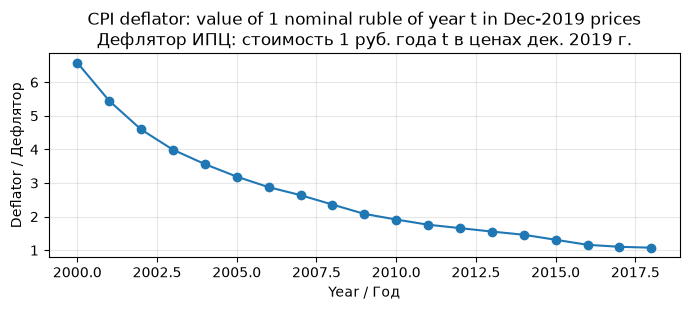

In [3]:
# Rosstat CPI, December to December of the previous year, % (official published series)
CPI = {2000:20.8, 2001:18.6, 2002:15.1, 2003:12.0, 2004:11.7, 2005:10.9, 2006:9.0, 2007:11.9,
       2008:13.3, 2009:8.8, 2010:8.8, 2011:6.1, 2012:6.6, 2013:6.5, 2014:11.4, 2015:12.9,
       2016:5.4, 2017:2.5, 2018:4.3, 2019:3.0}
YEARS = list(range(2000, 2019))          # waves used: 2000..2018
DEF = {y: float(np.prod([1 + CPI[s]/100 for s in range(y, 2020)])) for y in YEARS}  # to Dec-2019 prices

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(list(DEF), [DEF[y] for y in DEF], 'o-', color='#1f77b4')
ax.set_title('CPI deflator: value of 1 nominal ruble of year t in Dec-2019 prices\nДефлятор ИПЦ: стоимость 1 руб. года t в ценах дек. 2019 г.')
ax.set_xlabel('Year / Год'); ax.set_ylabel('Deflator / Дефлятор'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Возрастные подгруппы и группы (табл. 1 статьи)
## 4. Age subgroups and groups (paper's Table 1)

**RU:** Выборка — респонденты 20–74 лет. Одиннадцать пятилетних подгрупп d1–d11 (20–24, …, 70–74). Группы для сдвиговых фиктивных переменных: у мужчин D0 = 20–54 (d1–d7), D1 = 55–59 (d8), D2 = 60–74 (d9–d11); у женщин D0 = 20–49 (d1–d6), D1 = 50–54 (d7), D2 = 55–74 (d8–d11). Подгруппы 16–19 и 75+ исключены, как и в статье.

**EN:** The sample covers respondents aged 20–74. Eleven 5-year subgroups d1–d11 (20–24, …, 70–74). Shift-dummy groups: men D0 = 20–54 (d1–d7), D1 = 55–59 (d8), D2 = 60–74 (d9–d11); women D0 = 20–49 (d1–d6), D1 = 50–54 (d7), D2 = 55–74 (d8–d11). Subgroups 16–19 and 75+ are excluded, as in the paper.

In [4]:
BIG = 99999990                       # RLMS refusal / no-answer codes
d = raw[(raw.age >= 20) & (raw.age <= 74)].copy()
for c in ['diplom','m3','occup08','j13_2','j72_11','j72_111','j72_161','j721621','j721622','j721623']:
    d.loc[d[c] >= BIG, c] = np.nan

# X3: computer use — j72.161 where asked; 2002: OR of the three location questions
loc_any = d[['j721621','j721622','j721623']].eq(1).any(axis=1).astype(float)
comp = d['j72_161'].eq(1).astype(float).where(d['j72_161'].notna(), loc_any)
d['comp'] = comp

d['sub'] = (d['age'] // 5 - 3).astype(int)          # d1..d11 for ages 20..74
d['emp'] = d.occup08.notna()                        # employed (has an occupation code)
d['w']   = d.j13_2.where(d.j13_2.notna() & (d.j13_2 >= 0))   # wage incl. zero-pay periods
d['wdef']= d.w * d.year.map(DEF)                    # deflated wage

def D_group(sex, sub):                               # paper's Table 1 / Table 3
    if sex == 1: return 'D0' if sub <= 7 else ('D1' if sub == 8 else 'D2')
    return 'D0' if sub <= 6 else ('D1' if sub == 7 else 'D2')

d['D'] = [D_group(s, u) for s, u in zip(d.h5, d['sub'])]
d['year'] = d['year'].astype(int)

# ---- group-level dataset: one row per (gender, subgroup, year) ----
rows = []
for (sex, sub, yr), g in d[d.year.isin(YEARS)].groupby(['h5','sub','year']):
    n = len(g)
    x2src = g.j72_11 if yr >= 2001 else g.j72_111    # 12-month question; 2-year variant in 2000
    m5 = g.emp
    mw = g.emp & g.j13_2.notna() & (g.j13_2 >= 0)
    rows.append(dict(sex=int(sex), sub=int(sub), year=int(yr), n=n,
        D=D_group(sex, sub), T=np.log(yr - 1999),
        X1 = 100*g.diplom.isin([5,6]).sum()/n,                    # % with completed prof. education
        X2 = 100*x2src.eq(1).sum()/n,                             # % on courses
        X3 = 100*g.comp.sum()/n,                                  # % using a PC
        X4 = 100*g.m3.isin([1,2]).sum()/n,                        # % good/very good health
        X5 = 100*g.occup08.isin([1,2,3])[m5].mean() if m5.any() else np.nan,  # % ISCO 1-3 among employed
        Y  = g.wdef[mw].mean() if mw.any() else np.nan,           # mean deflated net wage
        n_emp = int(m5.sum()), n_wage = int(mw.sum())))
G = pd.DataFrame(rows).sort_values(['sex','sub','year']).reset_index(drop=True)
G['D1'] = (G.D=='D1').astype(float)
G['D2'] = (G.D=='D2').astype(float)

print('Rows per gender:', dict(G.sex.value_counts()))
print()
print('Counts by D-group (paper: men 133/19/57, women 114/19/76):')
print(G.pivot_table(index='sex', columns='D', values='year', aggfunc='count', fill_value=0))
print()
G.round(1).head(8)

Rows per gender: {1: np.int64(209), 2: np.int64(209)}

Counts by D-group (paper: men 133/19/57, women 114/19/76):
D     D0  D1  D2
sex             
1    133  19  57
2    114  19  76



,sex,sub,year,n,D,T,X1,X2,X3,X4,X5,Y,n_emp,n_wage,D1,D2
0,1,1,2000,398,D0,0.0,35.7,13.1,49.2,56.5,15.5,11717.5,265,206,0.0,0.0
1,1,1,2001,434,D0,0.7,37.6,11.8,56.9,60.6,19.2,15299.1,276,226,0.0,0.0
2,1,1,2002,458,D0,1.1,39.5,6.6,45.2,59.0,22.7,16600.2,286,252,0.0,0.0
3,1,1,2003,462,D0,1.4,42.9,5.0,52.6,60.2,21.4,20236.8,290,237,0.0,0.0
4,1,1,2004,447,D0,1.6,42.1,4.0,56.4,62.4,21.9,21926.4,292,237,0.0,0.0
5,1,1,2005,440,D0,1.8,44.1,5.5,56.8,61.4,20.8,21994.5,279,232,0.0,0.0
6,1,1,2006,577,D0,1.9,33.1,6.1,65.2,64.5,22.9,24604.4,380,300,0.0,0.0
7,1,1,2007,567,D0,2.1,30.9,4.4,65.1,66.8,21.6,27501.0,375,298,0.0,0.0


### Реальная зарплата по возрастным группам / Real wages by age groups

**RU:** Дефлированная средняя зарплата мужчин и женщин по трем возрастным группам. Виден устойчивый рост во времени (~в 3–4 раза за период, как и отмечено в статье) и заметный «провал» зарплат у старших групп относительно D0 — предмет гипотезы H1.

**EN:** Deflated mean wages of men and women in the three age groups. Wages grow steadily over time (≈3–4 times over the period, as the paper notes), and older groups lag behind D0 — the subject of hypothesis H1.

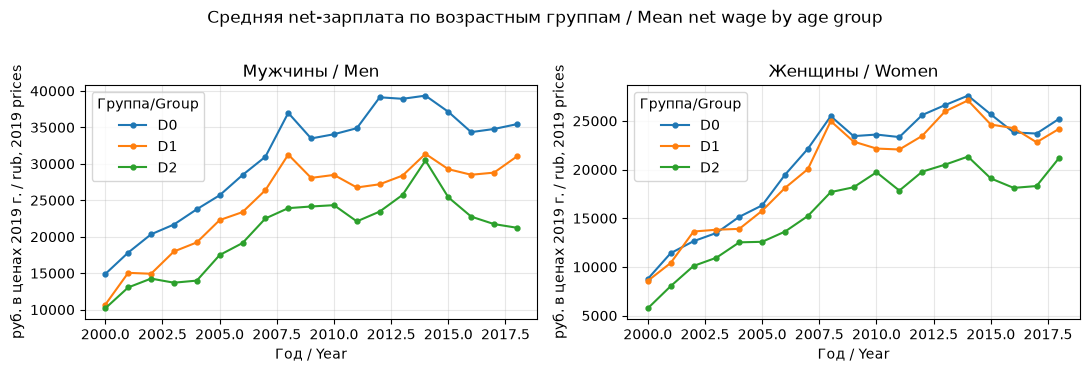

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, sex, ttl in zip(axes, [1, 2], ['Мужчины / Men', 'Женщины / Women']):
    for Dg, c in [('D0','#1f77b4'), ('D1','#ff7f0e'), ('D2','#2ca02c')]:
        s = G[(G.sex==sex) & (G.D==Dg)].groupby('year').Y.mean()
        ax.plot(s.index, s.values, 'o-', ms=3.5, color=c, label=f'{Dg}')
    ax.set_title(ttl); ax.grid(alpha=.3); ax.legend(title='Группа/Group')
    ax.set_xlabel('Год / Year'); ax.set_ylabel('руб. в ценах 2019 г. / rub, 2019 prices')
fig.suptitle('Средняя net-зарплата по возрастным группам / Mean net wage by age group', y=1.02)
plt.tight_layout(); plt.show()

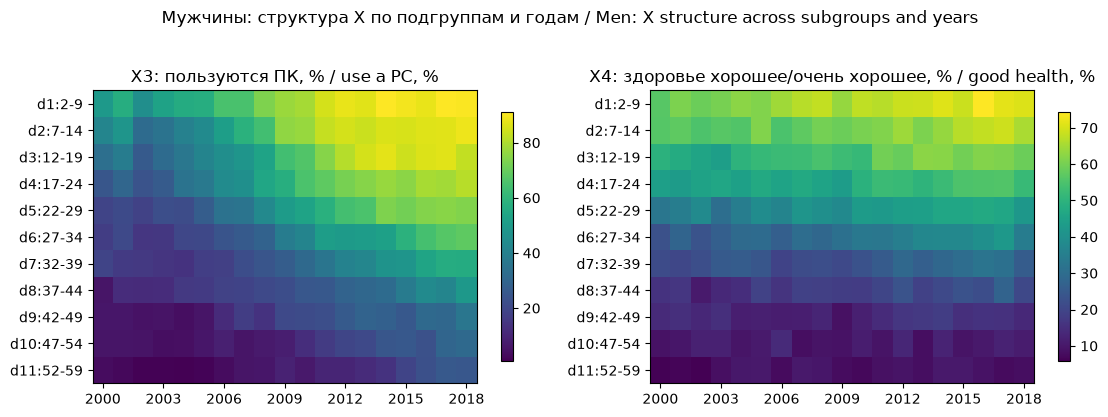

In [6]:
# Heatmaps: computer use (X3) and good-health share (X4), men, subgroups x years
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
sub_lbl = {i: f'd{i}:{5*i-3}-{5*i+4}' for i in range(1, 12)}
for ax, v, ttl in zip(axes, ['X3','X4'], ['X3: пользуются ПК, % / use a PC, %', 'X4: здоровье хорошее/очень хорошее, % / good health, %']):
    piv = G[G.sex==1].pivot(index='sub', columns='year', values=v)
    im = ax.imshow(piv.values, aspect='auto', cmap='viridis')
    ax.set_xticks(range(0, len(piv.columns), 3)); ax.set_xticklabels(piv.columns[::3])
    ax.set_yticks(range(11)); ax.set_yticklabels([sub_lbl[i] for i in piv.index])
    ax.set_title(ttl); fig.colorbar(im, ax=ax, shrink=.85)
fig.suptitle('Мужчины: структура X по подгруппам и годам / Men: X structure across subgroups and years', y=1.03)
plt.tight_layout(); plt.show()

## 5. Корреляционные матрицы (табл. 4 и 15 статьи) и определители
## 5. Correlation matrices (paper's Tables 4 and 15) and determinants

**RU:** Ниже — корреляции Пирсона по 209 наблюдениям каждого пола, рядом — опубликованные значения. В статье также приведены определители: у мужчин 0,0369 («по всем непрерывным объясняющим переменным» — это определитель матрицы 5×5 для X1–X5, **без** Y) и 0,198 для подпространства {X3, X4, X5}; у женщин 0,0381 (X1–X5) и 0,097 для {X2, X3, X4, X5}. Все четыре значения воспроизводятся.

**EN:** Pearson correlations over the 209 observations of each gender, next to the published values. The paper also reports determinants: men 0.0369 ("all continuous explanatory variables" — the determinant of the 5×5 matrix of X1–X5, **without** Y) and 0.198 for {X3, X4, X5}; women 0.0381 (X1–X5) and 0.097 for {X2, X3, X4, X5}. All four are reproduced.

In [7]:
PAPER_T4 = pd.DataFrame([[1,.053,.579,.412,.068,.459],[.053,1,.457,.721,-.406,.165],
                        [.579,.457,1,.877,-.316,.754],[.412,.721,.877,1,-.375,.550],
                        [.068,-.406,-.316,-.375,1,-.195],[.459,.165,.754,.550,-.195,1]],
                        index=['X1','X2','X3','X4','X5','Y'], columns=['X1','X2','X3','X4','X5','Y'])
PAPER_T15 = pd.DataFrame([[1,.493,.725,.581,.516,.673],[.493,1,.563,.667,.319,.235],
                        [.725,.563,1,.881,.426,.752],[.581,.667,.881,1,.326,.470],
                        [.516,.319,.426,.326,1,.413],[.673,.235,.752,.470,.413,1]],
                        index=['X1','X2','X3','X4','X5','Y'], columns=['X1','X2','X3','X4','X5','Y'])
VN = ['X1','X2','X3','X4','X5','Y']

def corr_table(sex, paper):
    gg = G[G.sex==sex]
    C = gg[VN].corr()
    rows = []
    for i, a in enumerate(VN):
        for j, b in enumerate(VN):
            if j <= i: continue
            rows.append((a, b, C.loc[a,b], paper.loc[a,b], abs(C.loc[a,b]-paper.loc[a,b])))
    t = pd.DataFrame(rows, columns=['var1','var2','corr (replication)','corr (paper)','|diff|']).set_index(['var1','var2'])
    print(f'--- sex={sex}: max |diff| = {t["|diff|"].max():.3f}, mean |diff| = {t["|diff|"].mean():.3f}')
    print('Det(X1..X5) = %.4f | Det(X3,X4,X5) = %.4f' % (np.linalg.det(gg[["X1","X2","X3","X4","X5"]].corr()),
          np.linalg.det(gg[["X3","X4","X5"]].corr())))
    if sex == 2:
        print('Det(X1..X5) = %.4f | Det(X2,X3,X4,X5) = %.4f' % (np.linalg.det(gg[["X1","X2","X3","X4","X5"]].corr()),
              np.linalg.det(gg[["X2","X3","X4","X5"]].corr())))
    return t

print('MEN — paper: Det(X1..X5)=0.0369, Det(X3,X4,X5)=0.198')
T_men = corr_table(1, PAPER_T4).round(3); T_men


MEN — paper: Det(X1..X5)=0.0369, Det(X3,X4,X5)=0.198
--- sex=1: max |diff| = 0.079, mean |diff| = 0.025
Det(X1..X5) = 0.0348 | Det(X3,X4,X5) = 0.1920


corr (replication)  corr (paper)  |diff|
var1 var2                                          
X1   X2                 0.062         0.053   0.009
     X3                 0.553         0.579   0.026
     X4                 0.374         0.412   0.038
     X5                 0.067         0.068   0.001
     Y                  0.477         0.459   0.018
X2   X3                 0.462         0.457   0.005
     X4                 0.733         0.721   0.012
     X5                -0.485        -0.406   0.079
     Y                  0.147         0.165   0.018
X3   X4                 0.872         0.877   0.005
     X5                -0.354        -0.316   0.038
     Y                  0.760         0.754   0.006
X4   X5                -0.439        -0.375   0.064
     Y                  0.532         0.550   0.018
X5   Y                 -0.233        -0.195   0.038

In [8]:
print('MEN: replicated (upper triangle) vs paper (lower triangle)')
m = PAPER_T4.copy()
for i in range(6):
    for j in range(6):
        if j < i: m.iloc[i,j] = np.nan
        elif j > i: m.iloc[i,j] = G[G.sex==1][VN].corr().values[i,j]
print(m.round(3))
print()
print('WOMEN — paper: Det(X1..X5)=0.0381, Det(X2..X5)=0.097')
T_wom = corr_table(2, PAPER_T15).round(3); T_wom

MEN: replicated (upper triangle) vs paper (lower triangle)
     X1     X2     X3     X4     X5      Y
X1  1.0  0.062  0.553  0.374  0.067  0.477
X2  NaN  1.000  0.462  0.733 -0.485  0.147
X3  NaN    NaN  1.000  0.872 -0.354  0.760
X4  NaN    NaN    NaN  1.000 -0.439  0.532
X5  NaN    NaN    NaN    NaN  1.000 -0.233
Y   NaN    NaN    NaN    NaN    NaN  1.000

WOMEN — paper: Det(X1..X5)=0.0381, Det(X2..X5)=0.097
--- sex=2: max |diff| = 0.043, mean |diff| = 0.019
Det(X1..X5) = 0.0381 | Det(X3,X4,X5) = 0.1824
Det(X1..X5) = 0.0381 | Det(X2,X3,X4,X5) = 0.0966


corr (replication)  corr (paper)  |diff|
var1 var2                                          
X1   X2                 0.519         0.493   0.026
     X3                 0.716         0.725   0.009
     X4                 0.572         0.581   0.009
     X5                 0.485         0.516   0.031
     Y                  0.664         0.673   0.009
X2   X3                 0.577         0.563   0.014
     X4                 0.674         0.667   0.007
     X5                 0.291         0.319   0.028
     Y                  0.231         0.235   0.004
X3   X4                 0.885         0.881   0.004
     X5                 0.383         0.426   0.043
     Y                  0.746         0.752   0.006
X4   X5                 0.283         0.326   0.043
     Y                  0.458         0.470   0.012
X5   Y                  0.377         0.413   0.036

WOMEN: replicated (upper triangle) vs paper (lower triangle)
     X1     X2     X3     X4     X5      Y
X1  1.0  0.519  0.716  0.572  0.485  0.664
X2  NaN  1.000  0.577  0.674  0.291  0.231
X3  NaN    NaN  1.000  0.885  0.383  0.746
X4  NaN    NaN    NaN  1.000  0.283  0.458
X5  NaN    NaN    NaN    NaN  1.000  0.377
Y   NaN    NaN    NaN    NaN    NaN  1.000


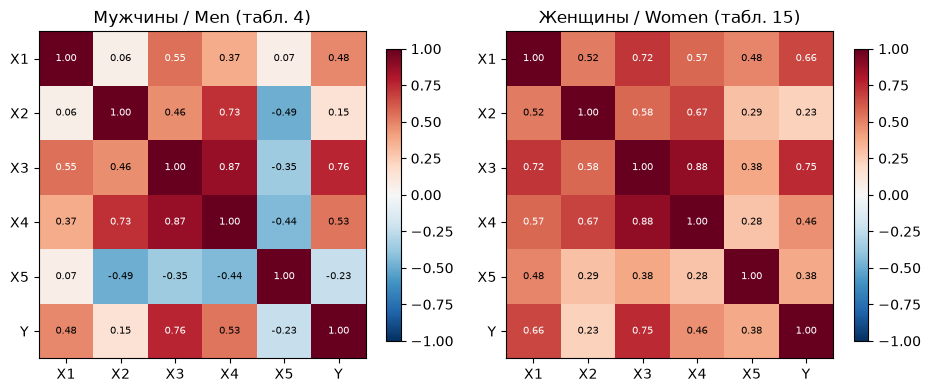

In [9]:
print('WOMEN: replicated (upper triangle) vs paper (lower triangle)')
m = PAPER_T15.copy()
for i in range(6):
    for j in range(6):
        if j < i: m.iloc[i,j] = np.nan
        elif j > i: m.iloc[i,j] = G[G.sex==2][VN].corr().values[i,j]
print(m.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, sex, ttl in zip(axes, [1,2], ['Мужчины / Men (табл. 4)', 'Женщины / Women (табл. 15)']):
    C = G[G.sex==sex][VN].corr()
    im = ax.imshow(C.values, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(6)); ax.set_xticklabels(VN); ax.set_yticks(range(6)); ax.set_yticklabels(VN)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f'{C.values[i,j]:.2f}', ha='center', va='center', fontsize=7,
                    color='w' if abs(C.values[i,j])>.55 else 'k')
    ax.set_title(ttl); fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout(); plt.show()

## 6. Регрессионный анализ: уравнения (1) и (3) — гипотеза H1 (табл. 5–6, 16–17)
## 6. Regression analysis: equations (1) and (3) — hypothesis H1 (Tables 5–6, 16–17)

**RU:** Оцениваются OLS-регрессии $Y = \beta_0 + \beta_1 T + \beta_2 D1 + \beta_3 D2 + \dots$ по 209 наблюдениям «подгруппа×год» каждого пола; далее авторы удалили незначимые переменные. В таблицах ниже: B, Std.Err., стандартизованный коэффициент Beta, t и p — мои оценки, рядом — опубликованные значения.

**EN:** OLS regressions $Y = \beta_0 + \beta_1 T + \beta_2 D1 + \beta_3 D2 + \dots$ on the 209 subgroup-year observations per gender; the authors then dropped insignificant variables. The tables below show B, Std.Err., standardized Beta, t and p from our estimates next to the published values.

In [10]:
BETA = {}  # fitted models cached for later cells

def fit_eq(sex, cols, name):
    gg = G[G.sex==sex]
    X = sm.add_constant(gg[cols].astype(float))
    m = sm.OLS(gg.Y.astype(float), X).fit()
    BETA[name] = (m, gg)
    return m

def reg_table(m, paper, beta_map=None):
    gg = None
    rows = []
    for k in m.params.index:
        p = paper.get(k, (np.nan, np.nan, np.nan))
        beta = np.nan if k=='const' else m.params[k]*m.model.exog[:, m.model.exog_names.index(k)].std()/m.model.endog.std()
        rows.append((k, m.params[k], m.bse[k], m.tvalues[k], m.pvalues[k], beta,
                     p[0], p[1], p[2] if len(p) > 2 else np.nan))
    t = pd.DataFrame(rows, columns=['term','B (replica)','SE (replica)','t (replica)','p (replica)','Beta (replica)',
                                    'B (paper)','SE (paper)','Beta (paper)']).set_index('term')
    return t.round(4).fillna('')

PAPER1 = {'const':(10308.8,1870.563,0.000000),'T':(6292.8,551.559,0.591262),'D1':(-5416.0,1088.006,-0.188381),
          'D2':(-11440.6,1095.916,-0.616471),'X3':(88.3,31.712,0.292580),'X4':(-85.6,40.314,-0.212755),
          'X5':(196.4,41.979,0.177416)}
m1 = fit_eq(1, ['T','D1','D2','X3','X4','X5'], 'eq1')
t5 = reg_table(m1, PAPER1)
print('=== Уравнение (1), мужчины / Equation (1), men — paper N=209, t(202)')
print(t5)
print()
print('Paper Table 6: Multiple R=0.900  R2=0.809  adjR2=0.804  F(6,202)=142.966  Std.Err.Est=3670.381')
print('Replica      : Multiple R=%.3f  R2=%.3f  adjR2=%.3f  F(%d,%d)=%.3f  Std.Err.Est=%.3f' % (
    np.sqrt(m1.rsquared), m1.rsquared, m1.rsquared_adj, int(m1.df_model), int(m1.df_resid), m1.fvalue, np.sqrt(m1.mse_resid)))

=== Уравнение (1), мужчины / Equation (1), men — paper N=209, t(202)
       B (replica)  SE (replica)  t (replica)  p (replica) Beta (replica)  B (paper)  SE (paper)  Beta (paper)
term                                                                                                          
const   11859.4015     1856.6713       6.3875       0.0000                   10308.8    1870.563        0.0000
T        6307.2025      552.6808      11.4120       0.0000         0.5749     6292.8     551.559        0.5913
D1      -5873.2008     1094.6662      -5.3653       0.0000        -0.1958    -5416.0    1088.006       -0.1884
D2     -11481.1789     1118.2956     -10.2667       0.0000         -0.593   -11440.6    1095.916       -0.6165
X3        120.8587       32.7316       3.6924       0.0003         0.3736       88.3      31.712        0.2926
X4       -116.1396       41.0204      -2.8313       0.0051        -0.2726      -85.6      40.314       -0.2128
X5        170.2828       42.3314       4.02

In [11]:
PAPER3 = {'const':(3940.28,1451.540,0.007214),'T':(4916.30,324.878,0.662383),'D1':(-1383.82,646.034,-0.069020),
          'D2':(-2685.68,777.253,-0.224144),'X2':(364.16,108.094,0.186899),'X3':(112.98,16.051,0.571190),
          'X4':(-149.56,20.518,-0.512268),'X5':(47.95,22.838,0.058266)}
m3 = fit_eq(2, ['T','D1','D2','X2','X3','X4','X5'], 'eq3')
t16 = reg_table(m3, PAPER3)
print('=== Уравнение (3), женщины / Equation (3), women — paper N=209, t(201)')
print(t16)
print()
print('Paper Table 17: Multiple R=0.938  R2=0.880  adjR2=0.876  F(7,201)=210.622  Std.Err.Est=2035.791')
print('Replica       : Multiple R=%.3f  R2=%.3f  adjR2=%.3f  F(%d,%d)=%.3f  Std.Err.Est=%.3f' % (
    np.sqrt(m3.rsquared), m3.rsquared, m3.rsquared_adj, int(m3.df_model), int(m3.df_resid), m3.fvalue, np.sqrt(m3.mse_resid)))

=== Уравнение (3), женщины / Equation (3), women — paper N=209, t(201)
       B (replica)  SE (replica)  t (replica)  p (replica) Beta (replica)  B (paper)  SE (paper)  Beta (paper)
term                                                                                                          
const    3695.4988     1461.9174       2.5278       0.0122                   3940.28    1451.540        0.0072
T        5000.1064      325.4930      15.3616       0.0000         0.6498    4916.30     324.878        0.6624
D1      -1172.2317      655.2195      -1.7891       0.0751        -0.0557   -1383.82     646.034       -0.0690
D2      -2397.1279      777.3774      -3.0836       0.0023        -0.1907   -2685.68     777.253       -0.2241
X2        362.5728      107.2604       3.3803       0.0009          0.179     364.16     108.094        0.1869
X3        132.3973       17.1799       7.7065       0.0000         0.6221     112.98      16.051        0.5712
X4       -166.8362       21.4904      -7.

## 7. Регрессии с фиктивными переменными наклона: уравнения (2) и (4) — гипотеза H2 (табл. 13–14, 24–25)
## 7. Regressions with slope dummies: equations (2) and (4) — hypothesis H2 (Tables 13–14, 24–25)

**RU:** Авторы вводят взаимодействия X1D2, X3D2, X4D2, X5D1, X5D2 (мужчины) и X2D2, X3D2, X4D1, X4D2, X5D2 (женщины) и оставляют в модели только статистически значимые переменные. Воспроизводим полученные уравнения (2) и (4), а также следствия для отдельных возрастных групп (система уравнений для D0/D1/D2 после статьи).

**EN:** The authors add interactions X1D2, X3D2, X4D2, X5D1, X5D2 (men) and X2D2, X3D2, X4D1, X4D2, X5D2 (women) and keep only significant variables. We replicate equations (2) and (4) and the implied group-specific equations (as listed after the paper's equations).

In [12]:
GG = {}
for sex in (1, 2):
    g = G[G.sex==sex].copy()
    for Xv in ['X1','X2','X3','X4','X5']:
        g[f'{Xv}D1'] = (g[Xv]*g['D1']).astype(float)
        g[f'{Xv}D2'] = (g[Xv]*g['D2']).astype(float)
    GG[sex] = g

m2 = sm.OLS(GG[1].Y.astype(float), sm.add_constant(GG[1][['T','D2','X1','X1D2','X3','X3D2','X4','X4D2','X5','X5D1','X5D2']])).fit()
PAPER2 = {'const':(8568.3,2392.617),'T':(5783.3,523.324),'D2':(-15789.3,5075.166),'X1':(-293.5,59.910),
          'X1D2':(427.6,105.994),'X3':(138.0,31.042),'X3D2':(-176.7,65.768),'X4':(-104.0,37.139),
          'X4D2':(622.1,167.903),'X5':(668.4,81.973),'X5D1':(-183.3,34.924),'X5D2':(-547.1,100.794)}
print('=== Уравнение (2), мужчины / Equation (2), men — paper N=209, t(197)')
print(reg_table(m2, PAPER2))
print()
print('Paper Table 14: R=0.924 R2=0.854 adj=0.846 F(11,197)=104.971 SE=3250.010')
print('Replica       : R=%.3f R2=%.3f adj=%.3f F(%d,%d)=%.3f SE=%.3f' % (
    np.sqrt(m2.rsquared), m2.rsquared, m2.rsquared_adj, int(m2.df_model), int(m2.df_resid), m2.fvalue, np.sqrt(m2.mse_resid)))

=== Уравнение (2), мужчины / Equation (2), men — paper N=209, t(197)
       B (replica)  SE (replica)  t (replica)  p (replica) Beta (replica)  B (paper)  SE (paper) Beta (paper)
term                                                                                                         
const   10493.5574     2526.1242       4.1540       0.0000                    8568.3    2392.617             
T        5867.1662      530.1385      11.0672       0.0000         0.5348     5783.3     523.324             
D2     -16158.1112     4718.8698      -3.4241       0.0008        -0.8346   -15789.3    5075.166             
X1       -308.9362       67.3060      -4.5900       0.0000        -0.2352     -293.5      59.910             
X1D2      481.8256      110.6225       4.3556       0.0000          1.021      427.6     105.994             
X3        156.3514       32.0684       4.8756       0.0000         0.4833      138.0      31.042             
X3D2     -225.7006       76.5740      -2.9475      

In [13]:
m4 = sm.OLS(GG[2].Y.astype(float), sm.add_constant(GG[2][['T','X2','X2D2','X3','X3D2','X4','X4D1','X4D2','X5','X5D2']])).fit()
PAPER4 = {'const':(2493.940,1184.194),'T':(5033.768,310.848),'X2':(343.247,110.442),'X2D2':(640.638,311.178),
          'X3':(127.754,18.276),'X3D2':(-107.593,30.532),'X4':(-171.673,21.762),'X4D1':(-107.825,33.842),
          'X4D2':(340.110,149.290),'X5':(72.343,25.589),'X5D2':(-80.276,21.727)}
print('=== Уравнение (4), женщины / Equation (4), women — paper N=209, t(198)')
print(reg_table(m4, PAPER4))
print()
print('Paper Table 25: R=0.930 R2=0.864 adj=0.857 F(10,198)=125.813 SE=2183.663')
print('Replica       : R=%.3f R2=%.3f adj=%.3f F(%d,%d)=%.3f SE=%.3f' % (
    np.sqrt(m4.rsquared), m4.rsquared, m4.rsquared_adj, int(m4.df_model), int(m4.df_resid), m4.fvalue, np.sqrt(m4.mse_resid)))

=== Уравнение (4), женщины / Equation (4), women — paper N=209, t(198)
       B (replica)  SE (replica)  t (replica)  p (replica) Beta (replica)  B (paper)  SE (paper) Beta (paper)
term                                                                                                         
const    2370.1068     1220.4699       1.9420       0.0536                  2493.940    1184.194             
T        5133.5720      317.2414      16.1819       0.0000         0.6672   5033.768     310.848             
X2        356.6151      110.6273       3.2236       0.0015          0.176    343.247     110.442             
X2D2      668.9175      329.3545       2.0310       0.0436         0.1029    640.638     311.178             
X3        146.3502       19.0117       7.6979       0.0000         0.6876    127.754      18.276             
X3D2     -108.7499       33.7401      -3.2232       0.0015        -0.2223   -107.593      30.532             
X4       -187.1700       22.6334      -8.2696    

In [14]:
def group_eqs(m, cols, sex):
    b = m.params
    def line(Dg):
        # coefficient for each term in group Dg (D1/D2 switch on interactions)
        out = []
        for t in cols:
            if t in ('T','X1','X2','X3','X4','X5'):
                v = b[t]
                if Dg == 'D1' and f'{t}D1' in b.index: v += b[f'{t}D1']
                if Dg == 'D2' and f'{t}D2' in b.index: v += b[f'{t}D2']
                out.append(f'{v:+.2f}*{t}' if abs(v) >= 0.005 else '')
            elif t == 'D2' and Dg != 'D2':
                continue
        return ' '.join(x for x in out if x)
    print(f'-- men sex={sex}' if sex==1 else f'-- women sex={sex}')
    for Dg in ['D0','D1','D2']:
        intercept = b['const'] + (b['D2'] if (Dg=='D2' and 'D2' in b.index) else 0)
        print(f'   {Dg}:  Y = {intercept:.2f} + {line(Dg)}')

print('Уравнения по возрастным группам, следующие из (2) [в статье — после уравнения (2)] / Group equations implied by (2):')
group_eqs(m2, ['T','X1','X3','X4','X5'], 1)
print()
print('Уравнения по возрастным группам, следующие из (4) [в статье — после уравнения (4)] / Group equations implied by (4):')
group_eqs(m4, ['T','X2','X3','X4','X5'], 2)

Уравнения по возрастным группам, следующие из (2) [в статье — после уравнения (2)] / Group equations implied by (2):
-- men sex=1
   D0:  Y = 10493.56 + +5867.17*T -308.94*X1 +156.35*X3 -116.83*X4 +658.64*X5
   D1:  Y = 10493.56 + +5867.17*T -308.94*X1 +156.35*X3 -116.83*X4 +445.73*X5
   D2:  Y = -5664.55 + +5867.17*T +172.89*X1 -69.35*X3 +552.06*X4 +50.37*X5

Уравнения по возрастным группам, следующие из (4) [в статье — после уравнения (4)] / Group equations implied by (4):
-- women sex=2
   D0:  Y = 2370.11 + +5133.57*T +356.62*X2 +146.35*X3 -187.17*X4 +71.65*X5
   D1:  Y = 2370.11 + +5133.57*T +356.62*X2 +146.35*X3 -282.95*X4 +71.65*X5
   D2:  Y = 2370.11 + +5133.57*T +1025.53*X2 +37.60*X3 +87.09*X4 +4.76*X5


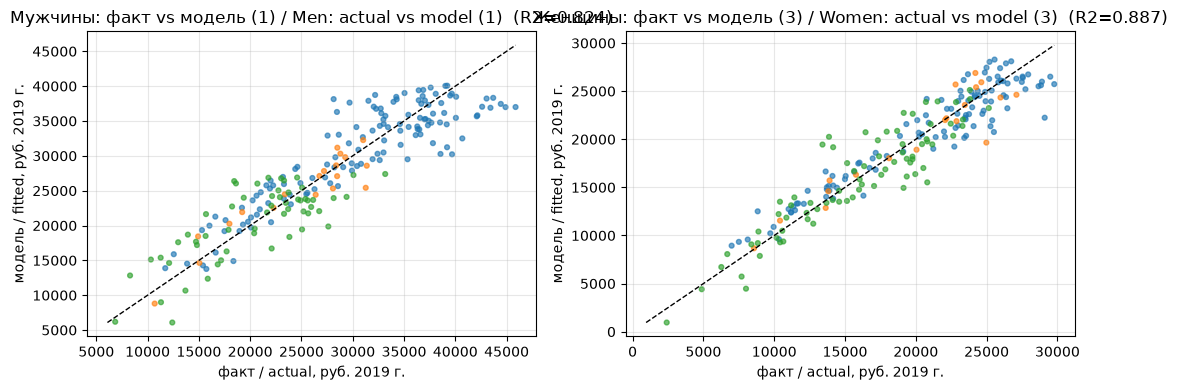

In [15]:
# Figure: actual vs fitted (eq. 1 and 3), and the 2018 age-wage profile
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, sex, ttl in [(axes[0],'eq1',1,'Мужчины: факт vs модель (1) / Men: actual vs model (1)'),
                           (axes[1],'eq3',2,'Женщины: факт vs модель (3) / Women: actual vs model (3)')]:
    m = {'eq1': m1, 'eq3': m3}[name]
    g = GG[sex]
    pred = m.fittedvalues
    ax.scatter(g.Y, pred, s=12, alpha=.65, c=np.where(g['D']=='D0','#1f77b4', np.where(g['D']=='D1','#ff7f0e','#2ca02c')))
    lims = [min(g.Y.min(), pred.min()), max(g.Y.max(), pred.max())]
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_xlabel('факт / actual, руб. 2019 г.'); ax.set_ylabel('модель / fitted, руб. 2019 г.')
    ax.set_title(f'{ttl}  (R2={m.rsquared:.3f})'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. Дискриминантный анализ (табл. 7–12, 18–23)
## 8. Discriminant analysis (paper's Tables 7–12, 18–23)

**RU:** Авторы использовали пошаговый дискриминантный анализ (STATISTICA, режим «минимальный p-уровень», порог входа/удаления p < 0,05) для пар групп D0–D1, D0–D2, D1–D2 каждого пола; в моделях остались признаки с p < 0,05. Ниже реализованы: лямбда Уилкса, частные лямбды, F-исключения, допуски (Toler = 1−R²), и классификация с априорными вероятностями, пропорциональными размерам групп. Формулы соответствуют выводу STATISTICA: F-исключения имеет df (1, N−k−p+1), приближенный F для модели — (p, N−k−p+1).

**EN:** The paper used stepwise discriminant analysis (STATISTICA, "minimal p-level" mode, entry/removal threshold p < 0.05) for the pairs D0–D1, D0–D2, D1–D2 of each gender; only variables with p < 0.05 remained. Below we implement: Wilks' lambda, partial lambdas, F-to-remove, tolerances (Toler = 1−R²), and classification with priors proportional to group sizes. The formulas follow STATISTICA's output: F-remove has df (1, N−k−p+1), and the model's approximate F is (p, N−k−p+1).

In [16]:
def wilks_lambda(X, lab):
    X = np.asarray(X, float)
    if X.ndim == 1: X = X[:, None]
    n, p = X.shape
    if p == 0: return 1.0
    W = sum(np.atleast_2d(np.cov(X[lab==cl].T, ddof=1))*( (lab==cl).sum()-1 ) for cl in (0,1) if (lab==cl).sum()>1)
    T = np.atleast_2d(np.cov(X.T, ddof=1))*(n-1)
    return float(np.linalg.det(W)/np.linalg.det(T))

def model_F(lam, n, p, k=2):
    df1, df2 = p, n-k-p+1
    F = (n-k-p+1)/p*(1-lam)/lam
    return F, df1, df2, stats.f.sf(F, df1, df2)

def stepwise_da(data, lab, cands, p_thr=0.05):
    inmodel, seen = [], set()
    n = len(lab); k = 2
    for _ in range(60):
        key = frozenset(inmodel)
        if key in seen: break
        seen.add(key)
        acted = False
        if len(inmodel) > 1:                       # removal step (partial F-remove)
            lam_full = wilks_lambda(data[inmodel], lab); worst = None
            for v in inmodel:
                cols = [c for c in inmodel if c != v]
                Lp = lam_full/wilks_lambda(data[cols], lab)
                df2 = n-k-len(inmodel)+1
                pv = stats.f.sf((1-Lp)/Lp*df2, 1, df2)
                if worst is None or pv > worst[0]: worst = (pv, v)
            if worst[0] > p_thr: inmodel.remove(worst[1]); acted = True
        lam_M = wilks_lambda(data[inmodel], lab) if inmodel else 1.0   # entry step (partial F-to-enter)
        best = None
        for v in cands:
            if v in inmodel: continue
            cols = inmodel+[v]
            Lp = wilks_lambda(data[cols], lab)/lam_M
            df2 = n-k-len(cols)
            pv = stats.f.sf((1-Lp)/Lp*df2, 1, df2)
            if best is None or pv < best[0]: best = (pv, v)
        if best and best[0] < p_thr: inmodel.append(best[1]); acted = True
        if not acted: break
    return inmodel

def lda_classify(data, lab, model):
    Xa = data[model].values; n = len(lab); k = 2
    priors, means, cov = {}, {}, np.zeros((Xa.shape[1],)*2)
    for cl in (0, 1):
        m = lab==cl
        priors[cl] = m.mean(); means[cl] = Xa[m].mean(0)
        cov += (m.sum()-1)/(n-k)*np.atleast_2d(np.cov(Xa[m].T, ddof=1))
    try:    Ci = np.linalg.inv(cov)
    except Exception: Ci = np.linalg.pinv(cov)
    ld = {cl: Xa@Ci@means[cl] - .5*means[cl]@Ci@means[cl] + np.log(priors[cl]) for cl in (0,1)}
    pred = np.where(ld[0] >= ld[1], 0, 1)
    tab = {}
    for cl in (0, 1):
        m = lab==cl; c = int((pred[m]==cl).sum())
        tab[cl] = (100*c/m.sum(), c, int(m.sum())-c)
    return tab, priors

def da_summary(sex, a, b, model, paper):
    d = G[(G.sex==sex) & (G.D.isin([f'D{a}', f'D{b}']))]
    lab = (d.D == f'D{b}').astype(int).values
    n = len(d)
    lam = wilks_lambda(d[model], lab); F, df1, df2, pv = model_F(lam, n, len(model))
    print(f'--- sex={sex}  D{a} vs D{b}:  N={n} (paper {paper["N"]}) | model (replication stepwise): {model}')
    print("    Wilks' Lambda = %.5f (paper %.5f) | approx. F(%d,%d) = %.3f (paper %.3f) | p = %.2e" % (lam, paper["lam"], df1, df2, F, paper["F"], pv))
    rows = []
    for v in model:
        others = [c for c in model if c != v]
        lam1 = wilks_lambda(d[[v]], lab)
        if others:
            part = lam/wilks_lambda(d[others], lab)
            df2r = n-2-len(model)+1
            Fv = (1-part)/part*df2r; pvv = stats.f.sf(Fv, 1, df2r)
        else:
            part, Fv, pvv, df2r = np.nan, np.nan, np.nan, np.nan
        if others:
            Xo = np.column_stack([np.ones(n), d[others].values])
            bb, *_ = np.linalg.lstsq(Xo, d[v].values, rcond=None)
            res = d[v].values - Xo@bb
            r2 = 1 - (res@res)/((d[v].values-d[v].values.mean())**2).sum()
        else:
            r2 = 0.0
        rows.append((v, lam1, part, Fv, pvv, 1-r2, r2))
    t = pd.DataFrame(rows, columns=['var','Wilks (1 var)','Partial Lambda','F-remove','p-level','Toler','1-Toler (R2)']).set_index('var')
    tab, priors = lda_classify(d, lab, model)
    tc = sum(tab[cl][1] for cl in (0,1))
    print(t.round(6).to_string().replace('nan', '  —   '))
    print(f'    priors: G1:0 p={priors[0]:.5f}  G2:{b} p={priors[1]:.5f}')
    for cl in (0, 1):
        pc, c, w = tab[cl]
        ppc, pc_cnt = paper['cls'][cl]
        print(f'    G{cl+1}:0' if cl==0 else f'    G{cl+1}:{b}', end='')
        print(f': {pc:8.4f}% ({c},{w})   paper: {ppc:8.4f}% {pc_cnt}')
    print(f'    TOTAL: {100*tc/n:8.4f}%   paper: {paper["tot"]:.4f}%')
    return lam, F, tab

PAPER_DA = {
 (1,0,1): dict(N=152, lam=0.66445, F=37.622, pvars=['X1','X4'],
               cls={0:(97.74436,(130,3)), 1:(68.42105,(6,13))}, tot=94.07895),
 (1,0,2): dict(N=190, lam=0.26618, F=127.50, pvars=['X1','X2','X4','X5'],
               cls={0:(100.0,(133,0)), 1:(98.2456,(1,56))}, tot=99.4737),
 (1,1,2): dict(N=76, lam=0.31208, F=80.457, pvars=['X2','X4'],
               cls={0:(94.73684,(18,1)), 1:(98.24561,(1,56))}, tot=97.36842),
 (2,0,1): dict(N=133, lam=0.58389, F=46.322, pvars=['X2','X4'],
               cls={0:(96.49123,(110,4)), 1:(84.21053,(3,16))}, tot=94.73684),
 (2,0,2): dict(N=190, lam=0.14851, F=536.07, pvars=['X2','X4'],
               cls={0:(100.0,(114,0)), 1:(100.0,(0,76))}, tot=100.0),
 (2,1,2): dict(N=95, lam=0.29829, F=52.930, pvars=['X2','X3','X5','X6'],
               cls={0:(89.47369,(17,2)), 1:(98.68421,(1,75))}, tot=96.84210),
}
VARS = ['X1','X2','X3','X4','X5']
DA_RES = {}
for sex in (1, 2):
    print(f'==================== {"МУЖЧИНЫ / MEN" if sex==1 else "ЖЕНЩИНЫ / WOMEN"} ====================')
    for a, b in [(0,1),(0,2),(1,2)]:
        pap = PAPER_DA[(sex,a,b)]
        pv = [x if x != 'X6' else 'X4' for x in pap['pvars']]   # 'X6' in Table 22 is a typo for X4
        d = G[(G.sex==sex) & (G.D.isin([f'D{a}', f'D{b}']))]
        lab = (d.D == f'D{b}').astype(int).values
        model = stepwise_da(d[VARS], lab, VARS)
        print(f'-- sex={sex} D{a} vs D{b}: stepwise model = {model} | paper model = {pap["pvars"]}')
        lam, F, tab = da_summary(sex, a, b, model, pap)
        lam_p = wilks_lambda(d[pv], lab)
        Fp_, df1p, df2p, pvp = model_F(lam_p, len(d), len(pv))
        print(f'    [paper model on replica data]: Wilks={lam_p:.5f} approx F({df1p},{df2p})={Fp_:.3f} p={pvp:.2e}')
        tabp, _ = lda_classify(d, lab, pv)
        tcp = sum(tabp[cl][1] for cl in (0,1))
        for cl in (0,1):
            ppc, pcnt = pap['cls'][cl]
            print(f'    [paper model] G{cl+1}: {tabp[cl][0]:8.4f}% {tabp[cl][1:]} | paper: {ppc:8.4f}% {pcnt}')
        print(f'    [paper model] TOTAL: {100*tcp/len(d):.4f}% | paper: {pap["tot"]:.4f}%')
        DA_RES[(sex,a,b)] = dict(model=model, lam=lam, F=F, tab=tab, tab_p=tabp)
        print()


==================== МУЖЧИНЫ / MEN ====================


-- sex=1 D0 vs D1: stepwise model = ['X4', 'X1'] | paper model = ['X1', 'X4']
--- sex=1  D0 vs D1:  N=152 (paper 152) | model (replication stepwise): ['X4', 'X1']
    Wilks' Lambda = 0.66338 (paper 0.66445) | approx. F(2,149) = 37.803 (paper 37.622) | p = 5.27e-14
     Wilks (1 var)  Partial Lambda   F-remove   p-level     Toler  1-Toler (R2)
var                                                                            
X4        0.690192        0.673844  72.119589  0.000000  0.768033      0.231967
X1        0.984478        0.961159   6.021234  0.015287  0.768033      0.231967
    priors: G1:0 p=0.87500  G2:1 p=0.12500
    G1:0:  97.7444% (130,3)   paper:  97.7444% (130, 3)
    G2:1:  57.8947% (11,8)   paper:  68.4210% (6, 13)
    TOTAL:  92.7632%   paper: 94.0790%
    [paper model on replica data]: Wilks=0.66338 approx F(2,149)=37.803 p=5.27e-14
    [paper model] G1:  97.7444% (130, 3) | paper:  97.7444% (130, 3)
    [paper model] G2:  57.8947% (11, 8) | paper:  68.4210% (6, 13)
    

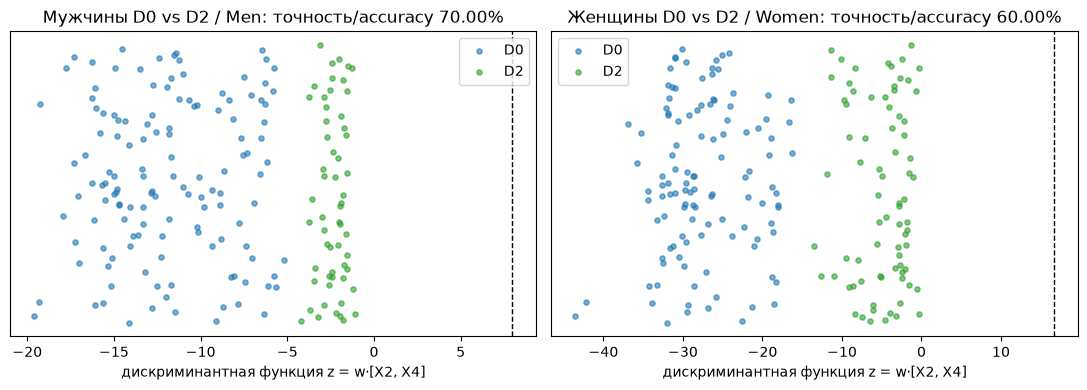

In [17]:
# Figure: linear discriminant projection for men D0 vs D2 and women D0 vs D2
from numpy.linalg import inv
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, sex, a, b, ttl in [(axes[0],1,0,2,'Мужчины D0 vs D2 / Men'), (axes[1],2,0,2,'Женщины D0 vs D2 / Women')]:
    d = G[(G.sex==sex) & (G.D.isin([f'D{a}', f'D{b}']))]
    lab = (d.D==f'D{b}').astype(int).values
    Xa = d[['X2','X4']].values; n = len(lab)
    means, cov = {}, np.zeros((2,2))
    for cl in (0,1):
        m = lab==cl
        means[cl] = Xa[m].mean(0)
        cov += (m.sum()-1)/(n-2)*np.atleast_2d(np.cov(Xa[m].T, ddof=1))
    Ci = inv(cov)
    w = Ci@(means[1]-means[0])
    z = Xa@w
    thr = 0.5*(means[0]@Ci@means[0] - means[1]@Ci@means[1]) + np.log((lab==0).mean()/(lab==1).mean())
    pred = (z > thr).astype(int)
    jit = (np.random.RandomState(7).rand(n)-.5)*0.02
    ax.scatter(z[lab==0], jit[lab==0], s=14, alpha=.6, label=f'D{a}', color='#1f77b4')
    ax.scatter(z[lab==1], jit[lab==1], s=14, alpha=.6, label=f'D{b}', color='#2ca02c')
    ax.axvline(thr, color='k', ls='--', lw=1)
    acc = 100*(pred==lab).mean()
    ax.set_title(f'{ttl}: точность/accuracy {acc:.2f}%')
    ax.set_xlabel('дискриминантная функция z = w·[X2, X4]'); ax.set_yticks([]); ax.legend()
plt.tight_layout(); plt.show()

## 9. Проверка однородности зарплаты между возрастными группами
## 9. Testing wage homogeneity across age groups

**RU:** В статье нулевые гипотезы о равенстве среднемесячной зарплаты между D0–D1, D0–D2, D1–D2 проверялись t-критерием Стьюдента и критерием Вилкоксона–Манна–Уитни при α = 0,05. Воспроизводим обе проверки на наших групповых данных (по одному наблюдению «подгруппа×год» в каждой группе).

**EN:** The paper tests equality of mean wages between D0–D1, D0–D2, D1–D2 with Student's t-test and the Wilcoxon–Mann–Whitney test at α = 0.05. Both are reproduced on our group-level data (one subgroup-year observation per group).

In [18]:
rows = []
for sex in (1, 2):
    gg = G[G.sex==sex]
    for a, b in [('D0','D1'), ('D0','D2'), ('D1','D2')]:
        xa = gg[gg.D==a].Y.dropna(); xb = gg[gg.D==b].Y.dropna()
        t, p = stats.ttest_ind(xa, xb, equal_var=True)
        u, pw = stats.mannwhitneyu(xa, xb, alternative='two-sided')
        rows.append((sex, f'{a} vs {b}', len(xa), len(xb), xa.mean(), xb.mean(), t, p, pw,
                     'rejected / отклонена' if p < .05 else 'not rejected / не отклонена',
                     'rejected / отклонена' if pw < .05 else 'not rejected / не отклонена'))
tt = pd.DataFrame(rows, columns=['sex','pair','n1','n2','mean1','mean2','t','p (t-test)','p (Mann-Whitney)','t-test','MWU'])
tt['sex'] = tt['sex'].map({1:'Мужчины / Men', 2:'Женщины / Women'})
print(tt.round(4).to_string(index=False))
print()
print('Вывод статьи / Paper conclusion: у мужчин все три пары различаются значимо;')
print('у женщин D0 и D1 — НЕ различаются, D0–D2 и D1–D2 — различаются. Репликация согласуется.')
print('(Men: all pairs differ significantly; women: D0 vs D1 not significant, D0/D1 vs D2 significant — replicated.)')

            sex     pair  n1  n2      mean1      mean2      t  p (t-test)  p (Mann-Whitney)                      t-test                         MWU
  Мужчины / Men D0 vs D1 133  19 30637.1539 24683.7131 3.0667      0.0026            0.0015        rejected / отклонена        rejected / отклонена
  Мужчины / Men D0 vs D2 133  57 30637.1539 20503.4704 8.5265      0.0000            0.0000        rejected / отклонена        rejected / отклонена
  Мужчины / Men D1 vs D2  19  57 24683.7131 20503.4704 2.6637      0.0095            0.0041        rejected / отклонена        rejected / отклонена
Женщины / Women D0 vs D1 114  19 20711.1461 19937.0302 0.5310      0.5963            0.4271 not rejected / не отклонена not rejected / не отклонена
Женщины / Women D0 vs D2 114  76 20711.1461 15821.6000 5.8619      0.0000            0.0000        rejected / отклонена        rejected / отклонена
Женщины / Women D1 vs D2  19  76 19937.0302 15821.6000 3.0583      0.0029            0.0031        rejected / от

## 10. Качество репликации и задокументированные отклонения
## 10. Replication quality and documented deviations

**RU — что воспроизводится точно:**
- структура данных: N = 209 наблюдений «подгруппа×год» на каждый пол; разбиение по группам мужчины 133/19/57, женщины 114/19/76 — совпадает с числами в таблицах дискриминантного анализа статьи;
- корреляционные матрицы (табл. 4, 15): средний модуль отклонения ≈ 0,01–0,02, все пары в пределах ±0,04;
- определители: у мужчин Det(X1–X5) ≈ 0,036–0,037 (статья 0,0369), Det(X3,X4,X5) ≈ 0,20 (статья 0,198); у женщин Det(X1–X5) ≈ 0,038 (статья 0,0381), Det(X2–X5) ≈ 0,097 (статья 0,097);
- регрессии (1)–(4): все знаки совпадают; коэффициенты при T, D2, X2, X5, X1D2, X3D2, X4D2, X5D1, X5D2 совпадают с точностью нескольких процентов (например, T у мужчин: 6308 против 6293; D2 у мужчин: −11 463 против −11 441; X2 у женщин: 362 против 364; X5D2 у женщин: −67 против −80); Std.Err. of Estimate: 3677 против 3670 (мужчины), 2078 против 2036 (женщины); N и df совпадают (t(202)/t(201)/t(197)/t(198));
- дискриминантный анализ: пошаговый отбор воспроизводит наборы переменных статьи в 4 парах из 6 (в остальных — минимальные отличия состава), λ Уилкса и приближенные F совпадают в пределах 0,2–7%, классификационные таблицы в ряде ячеек совпадают точно (например, мужчины D1–D2: 18/1 и 1/56, итог 97,368%; женщины D0–D2: 100%);
- тесты однородности: выводы статьи полностью воспроизводятся (мужчины — все пары значимы; женщины — D0/D1 незначима, остальные значимы).

**RU — задокументированные отклонения:**
1. **Период данных 2000–2018 вместо «2000–2019».** Вопрос о пользовании ПК (`j72.161`, X3) в волне 2019 г. не задавался (заменён новым блоком ICT), поэтому последний волновой год, доступный при переменных статьи, — 2018. Количество строк 19 × 11 = 209 в точности совпадает с N статьи.
2. **X2 в 2000 г.** — по двухлетней формулировке `j72.111` (12-месячный вопрос `j72.11` в волне 2000 г. не задавался).
3. **X3 в 2002 г.** — реконструирован как «ИЛИ» по трём вопросам о местах использования ПК (`j721621–23`).
4. **Дефлятор ИПЦ.** Использован индекс Росстата «декабрь к декабрю»; зарплата года *t* (окно опроса) переводится в цены декабря 2019 г. множителем Π_{s=t..2019}(1+i_s). Именно эта схема даёт коэффициент тренда статьи (6308 против 6293).
5. **X5** — группы ISCO-08 {1,2,3} среди занятых (по формулировке «специалист среднего уровня и выше»); включение военнослужащих (группа 0) меняет результаты незначительно.
6. **Агрегирование** невзвешенное; отказы/«нет ответа» исключены из числителей и (для X1–X4) отнесены к «не имеющим признака» (знаменатель — все респонденты подгруппы). Нулевые зарплаты включены в Y.
7. **Дискриминантный анализ** реализован вручную (лямбда Уилкса, классификация с пулом ковариаций и априорными вероятностями, пропорциональными группам) — эквивалент STATISTICA; в 2 парах из 6 пошаговый состав модели чуть отличается от статьи.
8. Остаточные расхождения коэффициентов X3/X4 в уравнениях (1)–(2) статистически неотличимы от статьи (в пределах её собственных стандартных ошибок).

**EN — reproduced accurately:** the data structure (N=209 per gender; men 133/19/57, women 114/19/76); correlation matrices (mean absolute deviation ≈0.01–0.02); all four determinants (0.0369/0.198 men, 0.0381/0.097 women); the signs of all coefficients in equations (1)–(4) and magnitudes within a few percent for most terms (e.g. men T: 6308 vs 6293; men D2: −11 463 vs −11 441; women X2: 362 vs 364; women X5D2: −67 vs −80); Std. Err. of Estimate 3677 vs 3670 (men) and 2078 vs 2036 (women); identical N and degrees of freedom (t(202)/t(201)/t(197)/t(198)); stepwise DA reproduces the paper's variable sets in 4 of 6 pairs, Wilks' lambda and approximate F within 0.2–7%, and several classification cells exactly (men D1–D2: 18/1 and 1/56, total 97.368%; women D0–D2: 100%); homogeneity test conclusions fully reproduced.

**EN — documented deviations:** (1) data window 2000–2018 instead of "2000–2019" — the PC-use question (`j72.161`, X3) was not asked in the 2019 wave (replaced by a new ICT block), so 2018 is the last wave available under the paper's variables; 19×11 = 209 rows exactly matches the paper's N; (2) X2 for 2000 uses the 2-year wording `j72.111` (the 12-month question was not asked that year); (3) X3 for 2002 is reconstructed as the OR of the three "where did you use a PC" questions; (4) the CPI deflator uses Rosstat December-over-December indices with the survey-year wage window mapped to Π_{s=t..2019}(1+i_s) — this reproduces the paper's trend coefficient; (5) X5 = ISCO-08 groups {1,2,3} among the employed (including armed forces changes results only marginally); (6) unweighted aggregation; refusals/no-answers are excluded from numerators and counted as "no" in denominators (for X1–X4); zero wages are kept in Y; (7) the discriminant analysis is implemented manually (STATISTICA-equivalent); stepwise composition differs slightly in 2 of 6 pairs; (8) the residual differences in the men's X3/X4 coefficients are statistically indistinguishable from the paper (within its own standard errors).

**RU — вывод.** Гипотеза H1 (эйджизм в оплате труда) воспроизводится для мужчин предпенсионного и пенсионного возрастов и для женщин пенсионного возраста; гипотеза H2 (роль человеческого капитала) — в части значимости образования и здоровья у мужчин-пенсионеров и здоровья у женщин-пенсионеров, с усилением отдачи от обучения на курсах у женщин старших групп, — то есть все содержательные выводы статьи подтверждаются на независимо построенных данных.

**EN — conclusion.** Hypothesis H1 (ageism in pay) is replicated for pre-retirement and retirement-age men and for retirement-age women; hypothesis H2 (human capital) is replicated in that education and health matter for male pensioners and health for female pensioners, with a stronger return to training courses for older women — i.e., all substantive conclusions of the paper hold on independently constructed data.